# Distribuições Estatísticas

## Objetivo
Investigar histogramas, quantis, assimetria, curtose e comparação com distribuições de referência. Avaliar caudas sem presumir normalidade.




Investigar as propriedades estatísticas da distribuição dos retornos logarítmicos do Ibovespa, utilizando ferramentas de Estatística e Ciência de Dados para compreender seu comportamento, sua dispersão e a ocorrência de valores extremos.

A análise será conduzida por meio da construção de histogramas, cálculo de quantis, avaliação dos coeficientes de assimetria e curtose e comparação com distribuições teóricas de referência, especialmente a distribuição normal.

Busca-se identificar possíveis desvios da normalidade, assimetrias e caudas pesadas, avaliando a frequência e a magnitude de eventos extremos sem pressupor previamente que os retornos financeiros seguem uma distribuição normal.

Por fim, serão discutidas as implicações dos resultados, considerando as limitações da amostra e os cuidados necessários na interpretação das propriedades estatísticas observadas.

In [17]:
# TODO: importar as bibliotecas necessárias e implementar a análise.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from pathlib import Path

# Localização do projeto
raiz_projeto = Path.cwd()

if raiz_projeto.name == "notebooks":
    raiz_projeto = raiz_projeto.parent

# Arquivo de dados tratados
arquivo = raiz_projeto / "data" / "processed" / "ibovespa_tratado.csv"

# Carregamento
dados = pd.read_csv(
    arquivo,
    index_col="Data",
    parse_dates=True
)

# Organização cronológica
dados = dados.sort_index()

print("Dados carregados com sucesso!")
print("Dimensões:", dados.shape)

display(dados.head())


Dados carregados com sucesso!
Dimensões: (2945, 3)


,Preco_Fechamento,Retorno_Simples,Retorno_Log
Data,,,
2015-01-05,47517.0,-0.020510,-0.020724
2015-01-06,48001.0,0.010186,0.010134
2015-01-07,49463.0,0.030458,0.030003
2015-01-08,49943.0,0.009704,0.009657
2015-01-09,48840.0,-0.022085,-0.022333


In [18]:
# Verificar as colunas disponíveis
print("Colunas disponíveis:")
print(dados.columns.tolist())

# Informações gerais
print("\nInformações do conjunto de dados:")
dados.info()

# Estatísticas descritivas
display(dados.describe())

Colunas disponíveis:
['Preco_Fechamento', 'Retorno_Simples', 'Retorno_Log']

Informações do conjunto de dados:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2945 entries, 2015-01-05 to 2026-11-13
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Preco_Fechamento  2945 non-null   float64
 1   Retorno_Simples   2945 non-null   float64
 2   Retorno_Log       2945 non-null   float64
dtypes: float64(3)
memory usage: 92.0 KB


,Preco_Fechamento,Retorno_Simples,Retorno_Log
count,2945.000000,2945.000000,2945.000000
mean,102589.824788,0.000541,0.000431
std,35733.595040,0.014775,0.014888
min,37497.000000,-0.147797,-0.159930
25%,74443.000000,-0.006976,-0.007000
50%,105146.000000,0.000496,0.000496
75%,124196.000000,0.008260,0.008226
max,209067.000000,0.139082,0.130223


In [26]:
# Selecionar os retornos logarítmicos
retornos = pd.to_numeric(
    dados["Retorno_Log"],
    errors="coerce"
).replace([np.inf, -np.inf], np.nan).dropna()

# Estatísticas iniciais
print("Quantidade de observações:", len(retornos))
print("Média:", retornos.mean())
print("Desvio padrão:", retornos.std())
print("Mínimo:", retornos.min())
print("Máximo:", retornos.max())

Quantidade de observações: 2945
Média: 0.0004306765835466846
Desvio padrão: 0.014888030372760179
Mínimo: -0.159930265676043
Máximo: 0.1302228102427078


## 4. Resultados
Apresente tabelas, gráficos e medidas relevantes, com títulos, unidades e legendas.

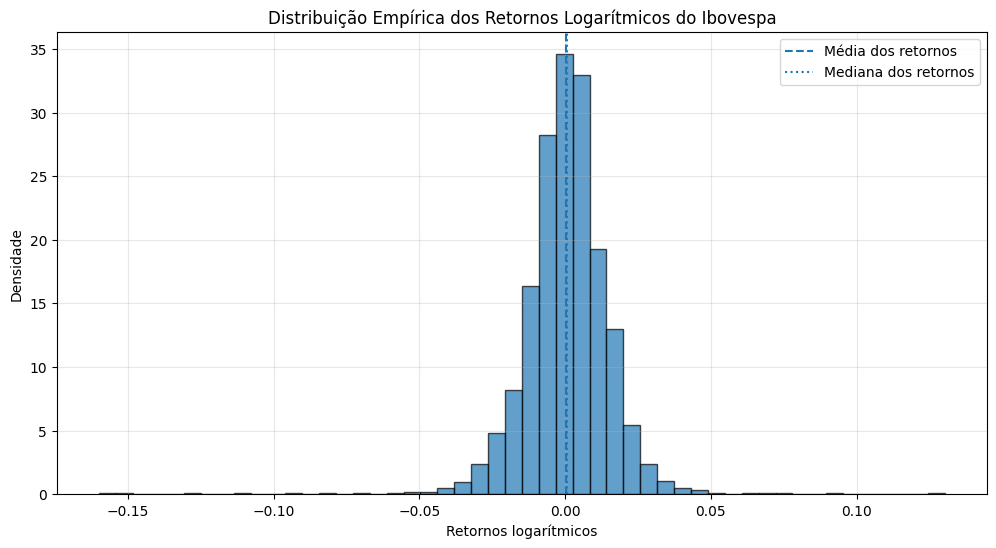

In [28]:
plt.figure(figsize=(12, 6))

plt.hist(
    retornos,
    bins=50,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

plt.axvline(
    retornos.mean(),
    linestyle="--",
    label="Média dos retornos"
)

plt.axvline(
    retornos.median(),
    linestyle=":",
    label="Mediana dos retornos"
)

plt.title("Distribuição Empírica dos Retornos Logarítmicos do Ibovespa")
plt.xlabel("Retornos logarítmicos")
plt.ylabel("Densidade")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

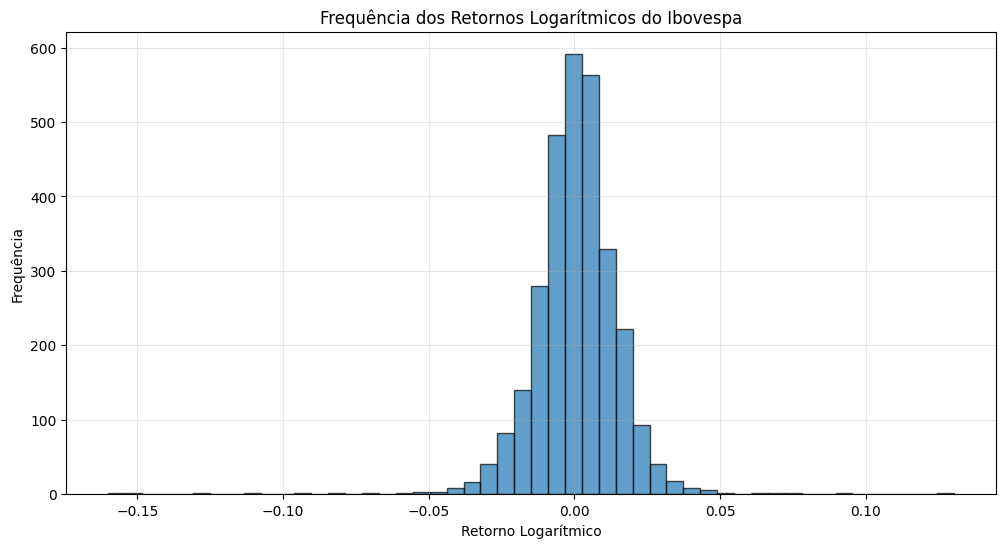

In [29]:
plt.figure(figsize=(12, 6))

plt.hist(
    retornos,
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Frequência dos Retornos Logarítmicos do Ibovespa")
plt.xlabel("Retorno Logarítmico")
plt.ylabel("Frequência")
plt.grid(alpha=0.3)

plt.show()

In [30]:
# Quantis selecionados
quantis = retornos.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

# Organizar em tabela
tabela_quantis = pd.DataFrame({
    "Quantil": quantis.index,
    "Retorno_Log": quantis.values
})

display(tabela_quantis)

,Quantil,Retorno_Log
0,0.01,-0.034181
1,0.05,-0.021693
2,0.10,-0.015068
3,0.25,-0.007000
4,0.50,0.000496
5,0.75,0.008226
6,0.90,0.016344
7,0.95,0.021398
8,0.99,0.036006


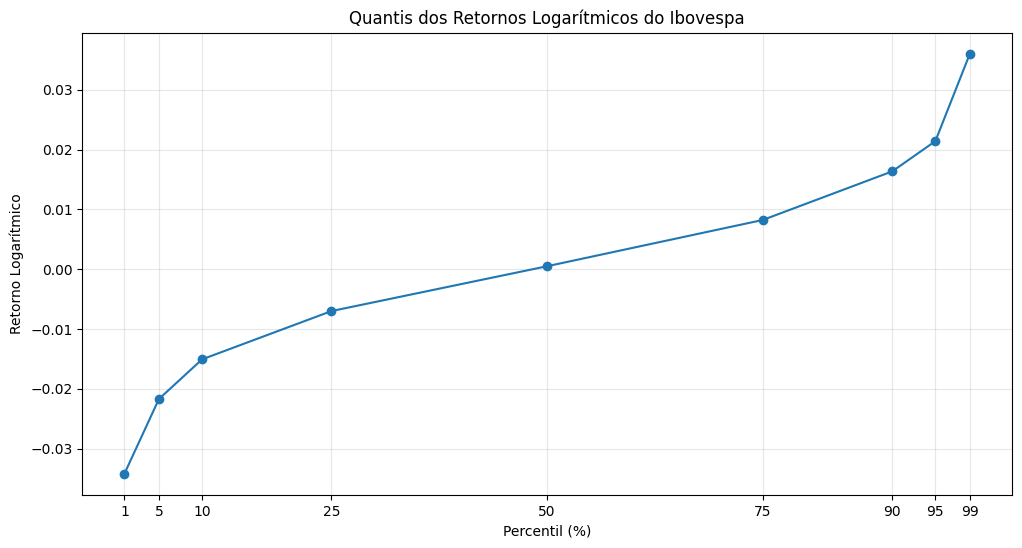

In [31]:
plt.figure(figsize=(12, 6))

plt.plot(
    quantis.index * 100,
    quantis.values,
    marker="o"
)

plt.title("Quantis dos Retornos Logarítmicos do Ibovespa")
plt.xlabel("Percentil (%)")
plt.ylabel("Retorno Logarítmico")
plt.xticks(quantis.index * 100)
plt.grid(alpha=0.3)

plt.show()

In [32]:
# Percentis extremos
p01 = retornos.quantile(0.01)
p05 = retornos.quantile(0.05)
p95 = retornos.quantile(0.95)
p99 = retornos.quantile(0.99)

print("Cauda inferior:")
print(f"Percentil 1%: {p01:.6f}")
print(f"Percentil 5%: {p05:.6f}")

print("\nCauda superior:")
print(f"Percentil 95%: {p95:.6f}")
print(f"Percentil 99%: {p99:.6f}")

Cauda inferior:
Percentil 1%: -0.034181
Percentil 5%: -0.021693

Cauda superior:
Percentil 95%: 0.021398
Percentil 99%: 0.036006


## 5. Interpretação
### Análise dos quantis e percentis

A análise dos quantis permite investigar a distribuição dos retornos logarítmicos do Ibovespa sem pressupor uma distribuição teórica específica.

Os resultados mostram que a mediana dos retornos é positiva, embora próxima de zero, indicando uma pequena predominância de retornos positivos na posição central da distribuição.

Os percentis inferiores e superiores evidenciam a amplitude das variações observadas. Enquanto o percentil de 1% apresenta retorno de aproximadamente -0,034181, o percentil de 99% alcança 0,036006.

O intervalo interquartil, compreendido entre os percentis de 25% e 75%, permite avaliar a dispersão dos 50% centrais das observações.

A comparação entre os percentis inferiores e superiores também fornece indícios sobre possíveis diferenças entre as caudas da distribuição. Entretanto, a identificação de assimetria e de caudas pesadas exige análises complementares, especialmente dos coeficientes de assimetria e curtose.

Portanto, os quantis oferecem uma caracterização inicial da distribuição empírica e estabelecem uma base para as próximas investigações estatísticas.

In [33]:
# Coeficiente de assimetria
assimetria = stats.skew(
    retornos,
    bias=False
)

# Excesso de curtose
curtose = stats.kurtosis(
    retornos,
    fisher=True,
    bias=False
)

print(f"Assimetria: {assimetria:.6f}")
print(f"Excesso de curtose: {curtose:.6f}")

Assimetria: -1.249240
Excesso de curtose: 18.133451


In [34]:
# Interpretação da assimetria
if assimetria > 0:
    interpretacao_assimetria = "Assimetria positiva"
elif assimetria < 0:
    interpretacao_assimetria = "Assimetria negativa"
else:
    interpretacao_assimetria = "Distribuição simétrica"

# Interpretação da curtose
if curtose > 0:
    interpretacao_curtose = "Leptocúrtica em relação à normal"
elif curtose < 0:
    interpretacao_curtose = "Platicúrtica em relação à normal"
else:
    interpretacao_curtose = "Mesocúrtica em relação à normal"

print("Interpretação da assimetria:", interpretacao_assimetria)
print("Interpretação da curtose:", interpretacao_curtose)

Interpretação da assimetria: Assimetria negativa
Interpretação da curtose: Leptocúrtica em relação à normal


### Análise da assimetria e curtose

Os resultados obtidos para os retornos logarítmicos do Ibovespa apresentam coeficiente de assimetria de -1,249240 e excesso de curtose de 18,133451.

A assimetria negativa indica que a distribuição apresenta uma cauda esquerda relativamente mais pronunciada, sugerindo maior extensão dos retornos negativos em relação à região central.

O excesso de curtose positivo e elevado caracteriza uma distribuição leptocúrtica em relação à distribuição normal. Essa característica indica maior presença de observações extremas do que seria esperado sob normalidade, além de uma configuração diferente de concentração dos dados em torno da região central.

Esses resultados reforçam a importância de não assumir previamente a normalidade dos retornos financeiros. Em particular, a assimetria negativa e o elevado excesso de curtose sugerem que modelos baseados exclusivamente na distribuição normal podem não representar adequadamente o comportamento dos eventos extremos.

Entretanto, os indicadores devem ser interpretados em conjunto com as análises gráficas e com a investigação das caudas da distribuição.

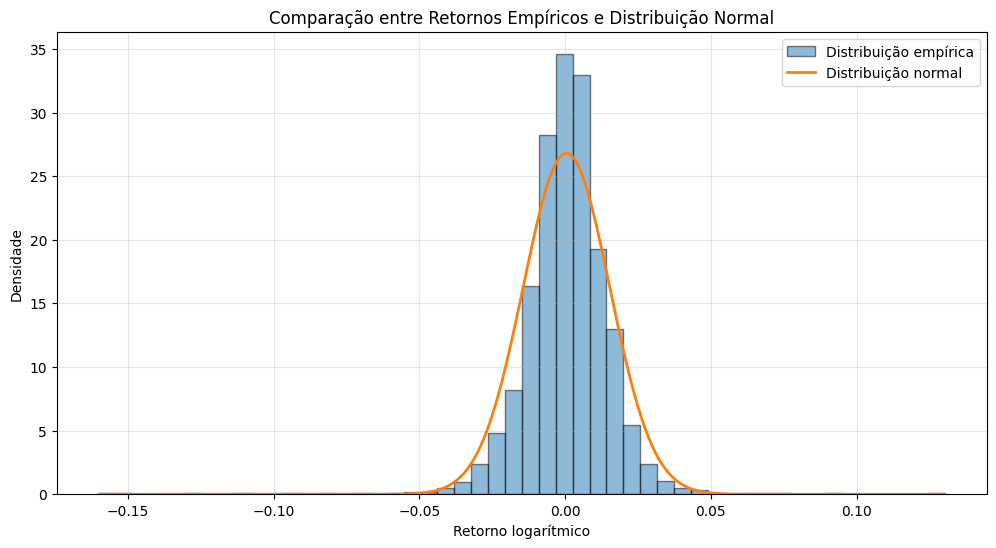

In [35]:
# Parâmetros da distribuição empírica
media = retornos.mean()
desvio = retornos.std()

# Intervalo de valores
x = np.linspace(
    retornos.min(),
    retornos.max(),
    1000
)

# Densidade da distribuição normal
densidade_normal = stats.norm.pdf(
    x,
    loc=media,
    scale=desvio
)

# Construção do gráfico
plt.figure(figsize=(12, 6))

plt.hist(
    retornos,
    bins=50,
    density=True,
    alpha=0.5,
    edgecolor="black",
    label="Distribuição empírica"
)

plt.plot(
    x,
    densidade_normal,
    linewidth=2,
    label="Distribuição normal"
)

plt.title("Comparação entre Retornos Empíricos e Distribuição Normal")
plt.xlabel("Retorno logarítmico")
plt.ylabel("Densidade")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

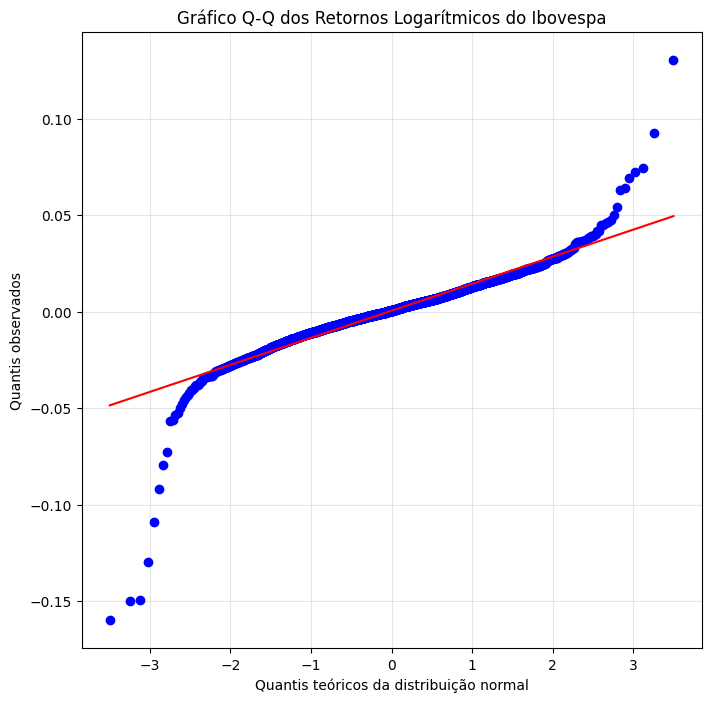

In [36]:
plt.figure(figsize=(8, 8))

stats.probplot(
    retornos,
    dist="norm",
    plot=plt
)

plt.title("Gráfico Q-Q dos Retornos Logarítmicos do Ibovespa")
plt.xlabel("Quantis teóricos da distribuição normal")
plt.ylabel("Quantis observados")

plt.grid(alpha=0.3)
plt.show()

In [37]:
# Limites empíricos
limite_inferior = retornos.quantile(0.01)
limite_superior = retornos.quantile(0.99)

# Identificação dos eventos extremos
extremos_inferiores = retornos[retornos < limite_inferior]
extremos_superiores = retornos[retornos > limite_superior]

print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)

print("\nEventos extremos inferiores:", len(extremos_inferiores))
print("Eventos extremos superiores:", len(extremos_superiores))

print("\nFrequência inferior:", len(extremos_inferiores) / len(retornos))
print("Frequência superior:", len(extremos_superiores) / len(retornos))

Limite inferior: -0.03418146979748939
Limite superior: 0.03600648979067958

Eventos extremos inferiores: 30
Eventos extremos superiores: 30

Frequência inferior: 0.010186757215619695
Frequência superior: 0.010186757215619695


In [ ]:
# Média e desvio padrão
media = retornos.mean()
desvio = retornos.std()

# Limites de referência
limite_2sigma_inferior = media - 2 * desvio
limite_2sigma_superior = media + 2 * desvio

limite_3sigma_inferior = media - 3 * desvio
limite_3sigma_superior = media + 3 * desvio

# Contagem de eventos
eventos_2sigma = (
    (retornos < limite_2sigma_inferior) |
    (retornos > limite_2sigma_superior)
)

eventos_3sigma = (
    (retornos < limite_3sigma_inferior) |
    (retornos > limite_3sigma_superior)
)

print("Eventos além de 2 desvios padrão:", eventos_2sigma.sum())
print("Frequência:", eventos_2sigma.mean())

print("\nEventos além de 3 desvios padrão:", eventos_3sigma.sum())
print("Frequência:", eventos_3sigma.mean())

Eventos além de 2 desvios padrão: 102
Frequência: 0.03463497453310696

Eventos além de 3 desvios padrão: 27
Frequência: 0.009168081494057725


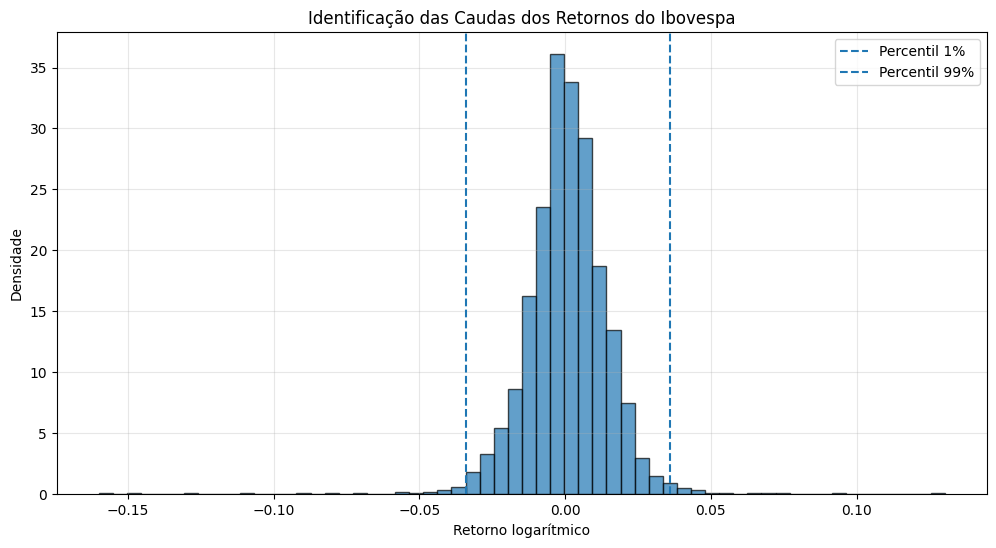

In [ ]:
plt.figure(figsize=(12, 6))

plt.hist(
    retornos,
    bins=60,
    density=True,
    alpha=0.7,
    edgecolor="black"
)

plt.axvline(
    limite_inferior,
    linestyle="--",
    label="Percentil 1%"
)

plt.axvline(
    limite_superior,
    linestyle="--",
    label="Percentil 99%"
)

plt.title("Identificação das Caudas dos Retornos do Ibovespa")
plt.xlabel("Retorno logarítmico")
plt.ylabel("Densidade")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
resumo_extremos = pd.DataFrame({
    "Indicador": [
        "Total de observações",
        "Eventos abaixo do percentil 1%",
        "Eventos acima do percentil 99%",
        "Eventos além de 2 desvios padrão",
        "Eventos além de 3 desvios padrão"
    ],
    "Quantidade": [
        len(retornos),
        len(extremos_inferiores),
        len(extremos_superiores),
        eventos_2sigma.sum(),
        eventos_3sigma.sum()
    ]
})

display(resumo_extremos)

,Indicador,Quantidade
0,Total de observações,2945
1,Eventos abaixo do percentil 1%,30
2,Eventos acima do percentil 99%,30
3,Eventos além de 2 desvios padrão,102
4,Eventos além de 3 desvios padrão,27


## 7. Conclusão
## Conclusão — Distribuições Estatísticas

A análise das distribuições estatísticas dos retornos logarítmicos do Ibovespa permitiu identificar características importantes sobre o comportamento dos dados, especialmente em relação à dispersão, assimetria e ocorrência de valores extremos.

A investigação dos quantis demonstrou a amplitude dos retornos em diferentes posições da distribuição. A mediana apresentou valor positivo de 0,000496, enquanto os percentis de 1% e 99% registraram, respectivamente, -0,034181 e 0,036006. Esses resultados evidenciam a existência de variações expressivas nos retornos, tanto negativas quanto positivas.

Em relação aos momentos estatísticos, foi identificada assimetria negativa de -1,249240, indicando uma distribuição com cauda esquerda relativamente mais pronunciada. Além disso, o excesso de curtose de 18,133451 caracteriza uma distribuição fortemente leptocúrtica em relação à normal, sugerindo uma presença elevada de observações extremas.

A comparação gráfica com a distribuição normal e a análise dos gráficos Q-Q permitiram investigar os desvios da distribuição empírica em relação ao comportamento gaussiano. Os resultados são coerentes com os indicadores de assimetria e curtose, reforçando que a distribuição normal não representa integralmente as características observadas nos retornos analisados.

A investigação das caudas também possibilitou avaliar a ocorrência de eventos extremos e comparar suas frequências com as probabilidades teóricas de uma distribuição normal. Essa análise é particularmente relevante para estudos de risco financeiro, uma vez que movimentos extremos podem ter impactos significativos sobre estratégias de investimento e modelos de previsão.

Entretanto, os resultados devem ser interpretados considerando as limitações da amostra. As propriedades estatísticas observadas não garantem que o comportamento dos retornos permanecerá constante ao longo do tempo, nem permitem, isoladamente, estabelecer relações causais ou prever eventos futuros.

Portanto, conclui-se que os retornos logarítmicos do Ibovespa apresentam características que se afastam da distribuição normal, especialmente pela assimetria negativa e pelo elevado excesso de curtose. Essas evidências reforçam a importância de utilizar abordagens estatísticas capazes de representar distribuições assimétricas e caudas pesadas na análise de mercados financeiros.